In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import ast
from itertools import combinations
from sklearn.preprocessing import MinMaxScaler

In [2]:
df_actions = pd.read_csv('actions.csv')
df_games = pd.read_csv('game_data.csv')
df_players = pd.read_csv('player_stats.csv')

In [3]:
df_actions

,state,name,seat,action,value,gameId
0,PREFLOP,gust,8,SB,0.5,787027613
1,PREFLOP,VegetablesArentYummy,9,BB,1.0,787027613
2,PREFLOP,StephCurry,1,fold,0.0,787027613
3,PREFLOP,PANDAisEVIL,2,fold,0.0,787027613
4,PREFLOP,AironVega,3,fold,0.0,787027613
...,...,...,...,...,...,...
15483152,PREFLOP,Orondi,3,fold,0.0,750640283
15483153,PREFLOP,WildHare,4,fold,0.0,750640283
15483154,PREFLOP,built2tilttttttttt,5,timed out,0.0,750640283
15483155,PREFLOP,built2tilttttttttt,5,fold,0.0,750640283


In [4]:
df_actions["state"].value_counts()

state
PREFLOP    11758334
FLOP        1896031
TURN        1085729
RIVER        743063
Name: count, dtype: int64

In [5]:
df_preflop = df_actions.copy()
df_preflop = df_preflop[df_preflop["state"] == "PREFLOP"]
df_preflop["state"].value_counts()

state
PREFLOP    11758334
Name: count, dtype: int64

In [6]:
df_preflop["action"].value_counts()

action
fold           5830395
SB             1378052
BB             1378052
raises         1294772
calls           843802
muck            765501
check            93917
sitting out      52651
timed out        44364
allin            42706
posts            14128
wait BB           9418
caps              8954
straddle          1613
bets                 9
Name: count, dtype: int64

In [7]:
df_players.columns

Index(['name', 'cards', 'bet', 'collect', 'win', 'lose', 'gameId'], dtype='object')

In [8]:
df_preflop.columns

Index(['state', 'name', 'seat', 'action', 'value', 'gameId'], dtype='object')

In [9]:
# Count distinct games per player
games_per_player = df_players.groupby("name")["gameId"].nunique()

# Keep only players with at least 20 games
eligible_players = games_per_player[games_per_player >= 20].index

df_players_filtered = df_players[df_players["name"].isin(eligible_players)]

In [10]:
# Keep only preflop actions of eligible players
df_preflop_filtered = df_preflop[df_preflop["name"].isin(eligible_players)].copy()

# Define VPIP actions
vpip_actions = {"calls", "raises", "bets", "allin", "straddle", "caps"}

# Define PFR actions
pfr_actions = {"raises", "bets", "allin"}

# Mark whether each action counts for VPIP / PFR
df_preflop_filtered["is_vpip"] = df_preflop_filtered["action"].isin(vpip_actions)
df_preflop_filtered["is_pfr"] = df_preflop_filtered["action"].isin(pfr_actions)

# Aggregate per player per game: did they VPIP/PFR in this game?
per_hand = df_preflop_filtered.groupby(["name", "gameId"]).agg(
    vpip=("is_vpip", "any"),
    pfr=("is_pfr", "any")
).reset_index()

In [11]:
per_hand

,name,gameId,vpip,pfr
0,!MushroomMan!,808314395,False,False
1,!MushroomMan!,808315057,False,False
2,!MushroomMan!,808315165,False,False
3,!MushroomMan!,808315222,True,True
4,!MushroomMan!,808315273,False,False
...,...,...,...,...
298118,zzXzz,794218143,False,False
298119,zzXzz,794218328,False,False
298120,zzXzz,794218472,False,False
298121,zzXzz,794218615,False,False


In [12]:
player_stats = per_hand.groupby("name").agg(
    hands_played=("gameId", "nunique"),
    vpip_count=("vpip", "sum"),
    pfr_count=("pfr", "sum")
)
player_stats

,hands_played,vpip_count,pfr_count
name,,,
!MushroomMan!,59,11,6
....,84,25,7
01001111,23,6,1
0nlyDaNuts,264,53,30
1000_na_nl25_aga,332,90,73
...,...,...,...
zboiii,151,24,17
zekezagura,159,52,34
zionnoiz,138,87,46


In [13]:
player_stats["VPIP"] = player_stats["vpip_count"] / player_stats["hands_played"]
player_stats["PFR"] = player_stats["pfr_count"] / player_stats["hands_played"]

player_stats = player_stats.reset_index()
player_stats

,name,hands_played,vpip_count,pfr_count,VPIP,PFR
0,!MushroomMan!,59,11,6,0.186441,0.101695
1,....,84,25,7,0.297619,0.083333
2,01001111,23,6,1,0.260870,0.043478
3,0nlyDaNuts,264,53,30,0.200758,0.113636
4,1000_na_nl25_aga,332,90,73,0.271084,0.219880
...,...,...,...,...,...,...
1572,zboiii,151,24,17,0.158940,0.112583
1573,zekezagura,159,52,34,0.327044,0.213836
1574,zionnoiz,138,87,46,0.630435,0.333333
1575,zitkojosh,46,28,11,0.608696,0.239130


In [14]:
def categorize_player(row):
    # Tight/Loose
    if row["VPIP"] < 0.20:
        style_vpip = "Tight"
    else:
        style_vpip = "Loose"
    
    # Passive/Aggressive
    if row["PFR"] < 0.15:
        style_pfr = "Passive"
    else:
        style_pfr = "Aggressive"
    
    return f"{style_vpip} {style_pfr}"

player_stats["style"] = player_stats.apply(categorize_player, axis=1)
player_stats

,name,hands_played,vpip_count,pfr_count,VPIP,PFR,style
0,!MushroomMan!,59,11,6,0.186441,0.101695,Tight Passive
1,....,84,25,7,0.297619,0.083333,Loose Passive
2,01001111,23,6,1,0.260870,0.043478,Loose Passive
3,0nlyDaNuts,264,53,30,0.200758,0.113636,Loose Passive
4,1000_na_nl25_aga,332,90,73,0.271084,0.219880,Loose Aggressive
...,...,...,...,...,...,...,...
1572,zboiii,151,24,17,0.158940,0.112583,Tight Passive
1573,zekezagura,159,52,34,0.327044,0.213836,Loose Aggressive
1574,zionnoiz,138,87,46,0.630435,0.333333,Loose Aggressive
1575,zitkojosh,46,28,11,0.608696,0.239130,Loose Aggressive


In [15]:
player_stats["style"].value_counts()

style
Loose Aggressive    830
Loose Passive       436
Tight Passive       272
Tight Aggressive     39
Name: count, dtype: int64

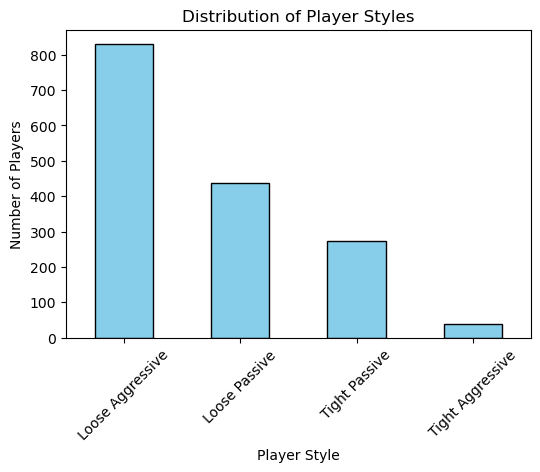

In [16]:
style_counts = player_stats["style"].value_counts()

plt.figure(figsize=(6,4))
style_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.ylabel("Number of Players")
plt.xlabel("Player Style")
plt.title("Distribution of Player Styles")
plt.xticks(rotation=45)
plt.show()

In [17]:
# Select features for clustering
X = player_stats[["VPIP", "PFR"]].values

In [18]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
player_stats["cluster"] = kmeans.fit_predict(X)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["VPIP", "PFR"])
print(centers)

       VPIP       PFR
0  0.545281  0.256832
1  0.189203  0.108788
2  0.395356  0.100396
3  0.301285  0.205445


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


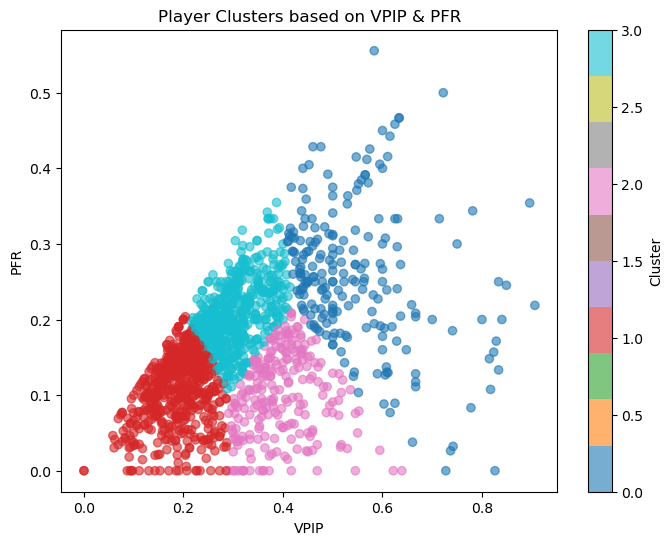

In [19]:
plt.figure(figsize=(8,6))
scatter = plt.scatter(
    player_stats["VPIP"], player_stats["PFR"],
    c=player_stats["cluster"], cmap="tab10", alpha=0.6
)
plt.xlabel("VPIP")
plt.ylabel("PFR")
plt.title("Player Clusters based on VPIP & PFR")
plt.colorbar(scatter, label="Cluster")
plt.show()

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


       VPIP       PFR
0  0.410236  0.184605
1  0.183099  0.088227
2  0.608648  0.252539
3  0.267052  0.180329


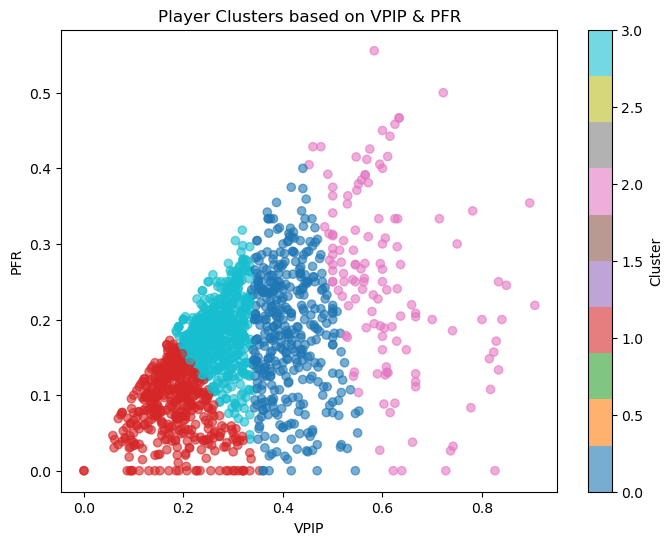

In [20]:
kmeans = KMeans(n_clusters=4, random_state=1, n_init=10)
player_stats["cluster"] = kmeans.fit_predict(X)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["VPIP", "PFR"])
print(centers)

plt.figure(figsize=(8,6))
scatter = plt.scatter(
    player_stats["VPIP"], player_stats["PFR"],
    c=player_stats["cluster"], cmap="tab10", alpha=0.6
)
plt.xlabel("VPIP")
plt.ylabel("PFR")
plt.title("Player Clusters based on VPIP & PFR")
plt.colorbar(scatter, label="Cluster")
plt.show()

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


       VPIP       PFR
0  0.267537  0.180164
1  0.610905  0.253591
2  0.411744  0.185082
3  0.183099  0.088227


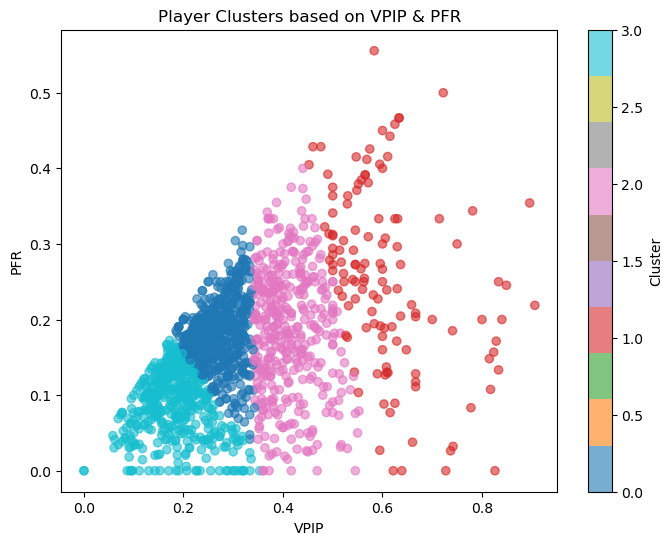

In [21]:
kmeans = KMeans(n_clusters=4, random_state=100, n_init=10)
player_stats["cluster"] = kmeans.fit_predict(X)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["VPIP", "PFR"])
print(centers)

plt.figure(figsize=(8,6))
scatter = plt.scatter(
    player_stats["VPIP"], player_stats["PFR"],
    c=player_stats["cluster"], cmap="tab10", alpha=0.6
)
plt.xlabel("VPIP")
plt.ylabel("PFR")
plt.title("Player Clusters based on VPIP & PFR")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [22]:
df_games

,gameId,duration,button,seats,players,endState,pot,rake,fee,board
0,787027613,59,7,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",PREFLOP,2.50,0.00,0.00,[]
1,787027929,91,8,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",RIVER,24.95,1.07,0.24,"[""6d"", ""5d"", ""6s"", ""7s"", ""7c""]"
2,787027464,24,6,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",PREFLOP,2.50,0.00,0.00,[]
3,787027410,63,6,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 100.0, ""name"": ""AironVeg...",TURN,6.18,0.22,0.10,"[""Jc"", ""6c"", ""8d"", ""10c""]"
4,787027157,43,5,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 101.0, ""name"": ""AironVeg...",PREFLOP,5.00,0.00,0.00,[]
...,...,...,...,...,...,...,...,...,...,...
1378047,750639343,29,1,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 50.0, ""name"": ""ROCKYII"",...",PREFLOP,1.25,0.00,0.00,[]
1378048,750639637,30,3,"[2, 3, 4, 5, 6]","[{""seat"": 2, ""chips"": 38.5, ""name"": ""Karas321""...",PREFLOP,0.50,0.00,0.00,[]
1378049,750639678,57,2,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 50.0, ""name"": ""ROCKYII"",...",TURN,2.14,0.09,0.02,"[""2h"", ""Qd"", ""Qh"", ""6h""]"
1378050,750640001,32,4,"[2, 3, 4, 5, 6]","[{""seat"": 2, ""chips"": 38.5, ""name"": ""Karas321""...",PREFLOP,2.50,0.00,0.00,[]


In [23]:
df_games["seats"] = df_games["seats"].apply(ast.literal_eval)
df_games["PlayerCount"] = df_games.apply(lambda df: len(list(df["seats"])), axis = 1)
df_games

,gameId,duration,button,seats,players,endState,pot,rake,fee,board,PlayerCount
0,787027613,59,7,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",PREFLOP,2.50,0.00,0.00,[],9
1,787027929,91,8,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",RIVER,24.95,1.07,0.24,"[""6d"", ""5d"", ""6s"", ""7s"", ""7c""]",9
2,787027464,24,6,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[{""seat"": 1, ""chips"": 105.78, ""name"": ""StephCu...",PREFLOP,2.50,0.00,0.00,[],9
3,787027410,63,6,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 100.0, ""name"": ""AironVeg...",TURN,6.18,0.22,0.10,"[""Jc"", ""6c"", ""8d"", ""10c""]",6
4,787027157,43,5,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 101.0, ""name"": ""AironVeg...",PREFLOP,5.00,0.00,0.00,[],6
...,...,...,...,...,...,...,...,...,...,...,...
1378047,750639343,29,1,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 50.0, ""name"": ""ROCKYII"",...",PREFLOP,1.25,0.00,0.00,[],6
1378048,750639637,30,3,"[2, 3, 4, 5, 6]","[{""seat"": 2, ""chips"": 38.5, ""name"": ""Karas321""...",PREFLOP,0.50,0.00,0.00,[],5
1378049,750639678,57,2,"[1, 2, 3, 4, 5, 6]","[{""seat"": 1, ""chips"": 50.0, ""name"": ""ROCKYII"",...",TURN,2.14,0.09,0.02,"[""2h"", ""Qd"", ""Qh"", ""6h""]",6
1378050,750640001,32,4,"[2, 3, 4, 5, 6]","[{""seat"": 2, ""chips"": 38.5, ""name"": ""Karas321""...",PREFLOP,2.50,0.00,0.00,[],5


In [24]:
df_games["PlayerCount"].describe()

count    1.378052e+06
mean     5.817797e+00
std      1.293733e+00
min      2.000000e+00
25%      5.000000e+00
50%      6.000000e+00
75%      6.000000e+00
max      9.000000e+00
Name: PlayerCount, dtype: float64

In [25]:
df_games.columns

Index(['gameId', 'duration', 'button', 'seats', 'players', 'endState', 'pot',
       'rake', 'fee', 'board', 'PlayerCount'],
      dtype='object')

In [26]:
per_hand_with_pc = per_hand.merge(
    df_games[["gameId", "PlayerCount"]],
    on="gameId",
    how="left"
)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


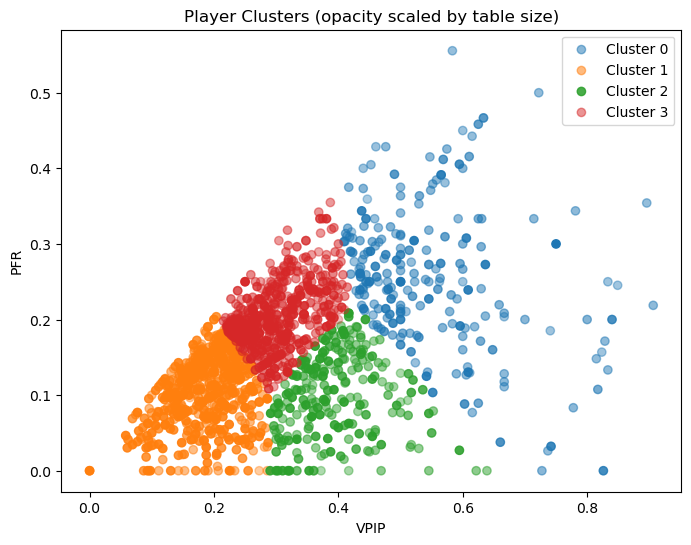

In [27]:
X = player_stats[["VPIP", "PFR"]].values

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
player_stats["cluster"] = kmeans.fit_predict(X)

# --- Step 2: Merge with PlayerCount (avg per player) ---
# If a player plays at multiple table sizes, you can take average PlayerCount
avg_pc = per_hand_with_pc.groupby("name")["PlayerCount"].mean()
player_stats = player_stats.merge(avg_pc, on="name", how="left")

# --- Step 3: Scale PlayerCount to opacity ---
# Normalize between 0.2 (min alpha) and 1.0 (max alpha)
pc = player_stats["PlayerCount"].values
alpha_scaled = (pc - pc.min()) / (pc.max() - pc.min())
alpha_scaled = 0.2 + 0.8 * alpha_scaled  # keep some minimum visibility

# --- Step 4: Scatter plot ---
plt.figure(figsize=(8,6))
for cluster in sorted(player_stats["cluster"].unique()):
    mask = player_stats["cluster"] == cluster
    plt.scatter(
        player_stats.loc[mask, "VPIP"],
        player_stats.loc[mask, "PFR"],
        alpha=alpha_scaled[mask],
        label=f"Cluster {cluster}"
    )

plt.xlabel("VPIP")
plt.ylabel("PFR")
plt.title("Player Clusters (opacity scaled by table size)")
plt.legend()
plt.show()

In [28]:
vpip_pfr_by_pc = per_hand_with_pc.groupby("PlayerCount").agg(
    avg_vpip=("vpip", "mean"),
    avg_pfr=("pfr", "mean"),
    samples=("gameId", "count")
).reset_index()

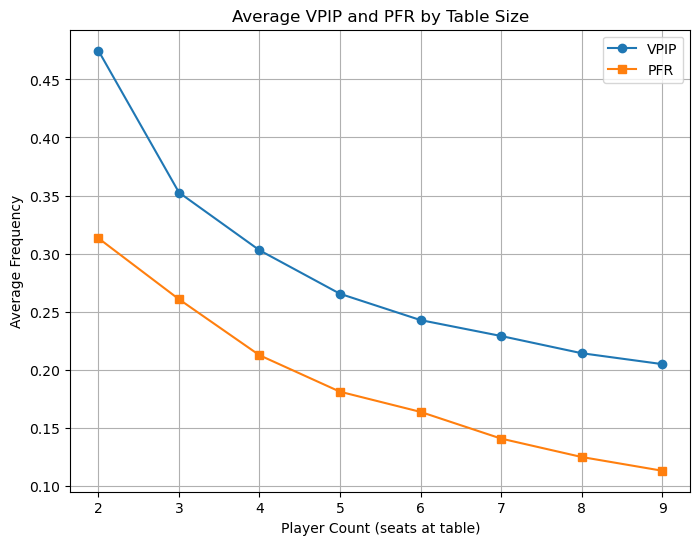

In [29]:
plt.figure(figsize=(8,6))

plt.plot(vpip_pfr_by_pc["PlayerCount"], vpip_pfr_by_pc["avg_vpip"],
         marker="o", label="VPIP")
plt.plot(vpip_pfr_by_pc["PlayerCount"], vpip_pfr_by_pc["avg_pfr"],
         marker="s", label="PFR")

plt.xlabel("Player Count (seats at table)")
plt.ylabel("Average Frequency")
plt.title("Average VPIP and PFR by Table Size")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
# 1. Global means
global_vpip = per_hand_with_pc["vpip"].mean()
global_pfr  = per_hand_with_pc["pfr"].mean()

# 2. Means per table size
means_by_pc = per_hand_with_pc.groupby("PlayerCount").agg(
    avg_vpip=("vpip", "mean"),
    avg_pfr=("pfr", "mean")
).reset_index()

# 3. Per-player-per-PC stats
player_stats_pc = per_hand_with_pc.groupby(["name", "PlayerCount"]).agg(
    hands_played=("gameId", "nunique"),
    vpip_count=("vpip", "sum"),
    pfr_count=("pfr", "sum")
).reset_index()

player_stats_pc["VPIP"] = player_stats_pc["vpip_count"] / player_stats_pc["hands_played"]
player_stats_pc["PFR"]  = player_stats_pc["pfr_count"] / player_stats_pc["hands_played"]

# 4. Merge with per-PC averages
player_stats_pc = player_stats_pc.merge(means_by_pc, on="PlayerCount", how="left")

# 5. Scale relative to global means
player_stats_pc["VPIP_scaled"] = player_stats_pc["VPIP"] * (global_vpip / player_stats_pc["avg_vpip"])
player_stats_pc["PFR_scaled"]  = player_stats_pc["PFR"]  * (global_pfr  / player_stats_pc["avg_pfr"])


player_weighted_scaled = player_stats_pc.groupby("name").apply(
    lambda g: pd.Series({
        "hands_played": g["hands_played"].sum(),
        "VPIP_scaled": (g["VPIP_scaled"] * g["hands_played"]).sum() / g["hands_played"].sum(),
        "PFR_scaled":  (g["PFR_scaled"]  * g["hands_played"]).sum() / g["hands_played"].sum()
    })
).reset_index()

scaler = MinMaxScaler()

player_weighted_scaled[["VPIP", "PFR"]] = scaler.fit_transform(
    player_weighted_scaled[["VPIP_scaled", "PFR_scaled"]]
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_556948\2906711746.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  player_weighted_scaled = player_stats_pc.groupby("name").apply(


In [31]:
X = player_weighted_scaled[["VPIP", "PFR"]].values

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
player_weighted_scaled["cluster"] = kmeans.fit_predict(X)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


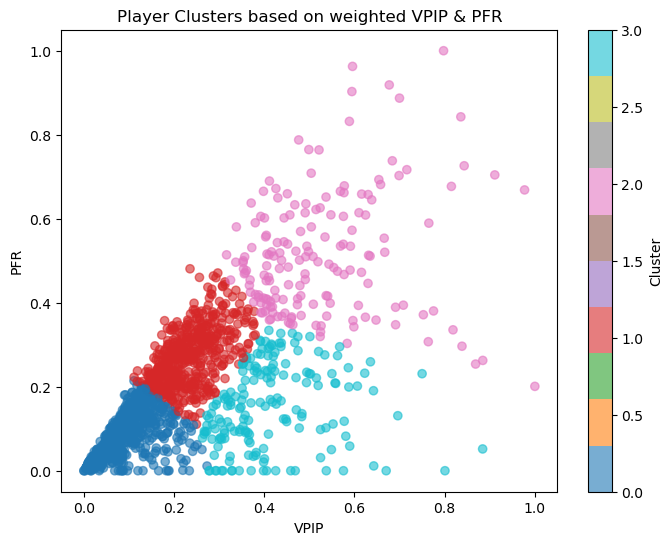

In [32]:
plt.figure(figsize=(8,6))
scatter = plt.scatter(
    player_weighted_scaled["VPIP"], player_weighted_scaled["PFR"],
    c=player_weighted_scaled["cluster"], cmap="tab10", alpha=0.6
)
plt.xlabel("VPIP")
plt.ylabel("PFR")
plt.title("Player Clusters based on weighted VPIP & PFR")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [33]:
player_weighted_scaled["style"] = player_weighted_scaled.apply(categorize_player, axis=1)
style_counts = player_weighted_scaled["style"].value_counts()

In [34]:
player_weighted_scaled

,name,hands_played,VPIP_scaled,PFR_scaled,VPIP,PFR,cluster,style
0,!MushroomMan!,59.0,8.443053,4.505513,0.218583,0.205644,1,Loose Aggressive
1,....,84.0,0.683908,0.209197,0.017706,0.009548,0,Tight Passive
2,01001111,23.0,1.496956,0.283612,0.038755,0.012945,0,Tight Passive
3,0nlyDaNuts,264.0,3.000034,1.833954,0.077668,0.083707,0,Tight Passive
4,1000_na_nl25_aga,332.0,3.008232,2.376588,0.077880,0.108474,0,Tight Passive
...,...,...,...,...,...,...,...,...
1572,zboiii,151.0,5.268045,4.241374,0.136385,0.193588,0,Tight Aggressive
1573,zekezagura,159.0,5.100864,3.976176,0.132057,0.181484,0,Tight Aggressive
1574,zionnoiz,138.0,24.123630,13.339295,0.624538,0.608843,2,Loose Aggressive
1575,zitkojosh,46.0,17.794701,8.022089,0.460688,0.366151,2,Loose Aggressive


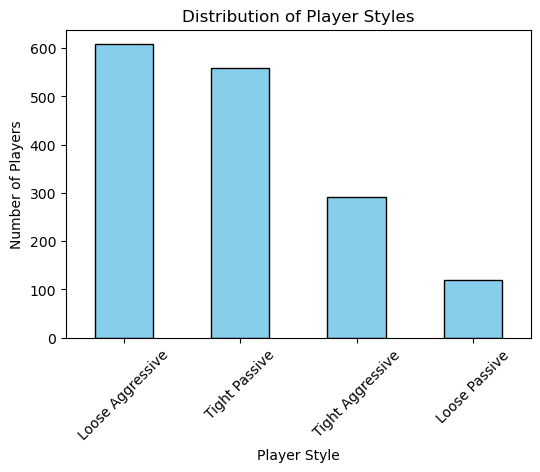

In [35]:
plt.figure(figsize=(6,4))
style_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.ylabel("Number of Players")
plt.xlabel("Player Style")
plt.title("Distribution of Player Styles")
plt.xticks(rotation=45)
plt.show()